In [1]:
##############################################################################################################################################################################################################################################################
### Create the reference for neurons

In [2]:
import sys
print(sys.executable) # Run the program in the Xenium environment you created

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/bin/python


In [5]:
import scanpy as sc
import pandas as pd
import numpy as np
import h5py
import anndata as ad
import matplotlib.pyplot as plt
import warnings
import os
import squidpy as sq
import spatialdata as sd
import spatialdata_io as sio
import spatialdata_plot
from scipy import sparse
from pathlib import Path
import seaborn as sns
CONFIG_DIR = Path("Notebooks")
sys.path.append(str(CONFIG_DIR))
import importlib
import xenium_config

importlib.reload(xenium_config)

<module 'xenium_config' from '/nfs/scistore23/sweengrp/sgobeil/Xenium Data Analysis/Xenium-MADM/Notebooks/xenium_config.py'>

In [6]:
sc.settings.verbosity = 3

In [7]:
### Load the data
adata_combined = sc.read_h5ad("Processed/Xenium_allcell_reference.h5ad")
adata_madm = sc.read_h5ad("Processed/MADM_preprocessed.h5ad")

In [8]:
### Make marker lists

#Import the marker list CSV
markers_df = pd.read_csv("Marker_Lists_v4.csv")

# Convert each column into a list, removing empty cells, and save them in a dictionary
marker_dict = {
    cell_type: markers_df[cell_type].dropna().tolist()
    for cell_type in markers_df.columns
}

# # Filter by markers actually present in the Xenium data
# marker_dict = {
#     cell_type: [
#         gene for gene in genes
#         if gene in adata_combined.var_names
#     ]
#     for cell_type, genes in marker_dict.items()
# }

custom_SC = {
    key: marker_dict[key]
    for key in xenium_config.custom_SC_keys
}

SC_neuron = {
    key: marker_dict[key]
    for key in xenium_config.SC_neuron_keys
}

Neuronal markers:
['Tubb3', 'Elavl3']
computing score 'neuron_score'
    finished: added
    'neuron_score', score of gene set (adata.obs).
    10 total control genes are used. (0:00:00)


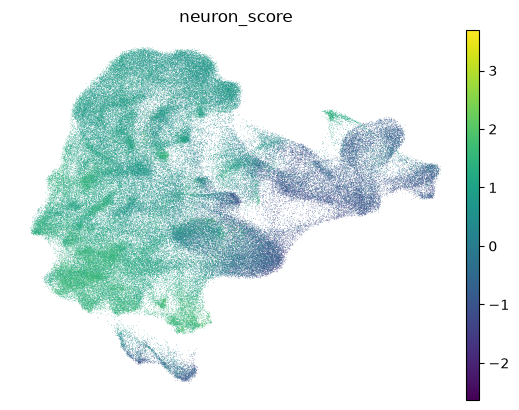

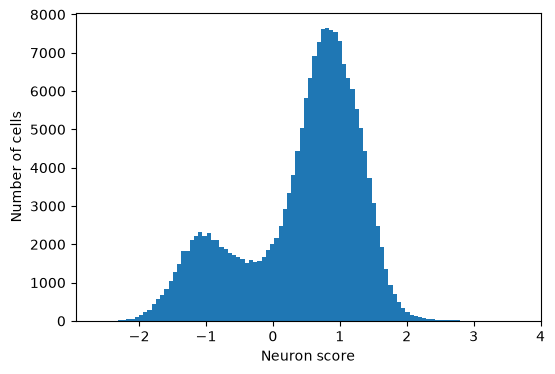

In [9]:
### Calculate a neuron score for each cell in preparation to subset only the neurons
# Use the lognorm transcript expression

neuron_markers = custom_SC["neurons"]

print("Neuronal markers:")
print(neuron_markers)

# Give each cell a neuron score
# for each cell, calculates the average log-normalized expression of the neuronal genes. It then subtracts the average expression of a set of control 
# genes chosen to have similar overall expression levels to the marker genes.
sc.tl.score_genes(
    adata_combined,
    gene_list=neuron_markers,
    score_name="neuron_score",
    layer="lognorm",
    use_raw=False
)

# Plot the neuron score on the UMAP of all cells
sc.pl.umap(
    adata_combined,
    color="neuron_score",
    cmap="viridis",
    frameon=False
)

plt.figure(figsize=(6, 4))

plt.hist(
    adata_combined.obs["neuron_score"],
    bins=100
)

plt.xlabel("Neuron score")
plt.ylabel("Number of cells")
plt.show()

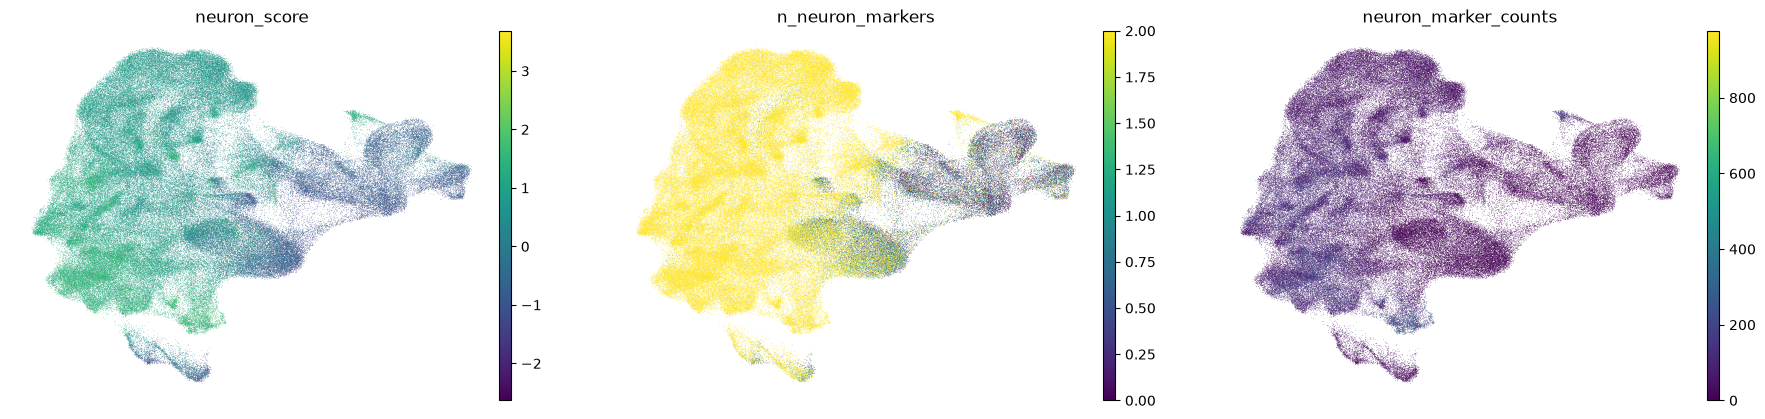

,neuron_score,n_neuron_markers,neuron_marker_counts
leiden,,,
0,-0.682674,1.0,2.0
1,-0.949644,0.0,0.0
2,-0.122922,2.0,6.0
3,1.075830,2.0,67.0
4,0.178232,2.0,17.0
5,0.635911,2.0,39.0
6,0.509329,2.0,10.0
7,1.353378,2.0,78.0
8,1.239792,2.0,69.0


In [10]:
### Inspect the neuron score in more detail

neuron_counts = adata_combined[:, neuron_markers].layers["counts"]

if sparse.issparse(neuron_counts):
    n_neuron_markers = np.asarray(
        (neuron_counts > 0).sum(axis=1)
    ).ravel()

    total_neuron_counts = np.asarray(
        neuron_counts.sum(axis=1)
    ).ravel()

else:
    n_neuron_markers = (neuron_counts > 0).sum(axis=1)
    total_neuron_counts = neuron_counts.sum(axis=1)

adata_combined.obs["n_neuron_markers"] = n_neuron_markers
adata_combined.obs["neuron_marker_counts"] = total_neuron_counts

sc.pl.umap(
    adata_combined,
    color=[
        "neuron_score",
        "n_neuron_markers",
        "neuron_marker_counts"
    ],
    frameon=False
)

adata_combined.obs.groupby(
    "leiden",
    observed=True
)[
    ["neuron_score", "n_neuron_markers", "neuron_marker_counts"]
].median()

All cells: 186,963
Neuronal subset: 89,673
Fraction retained: 48.0%
... be careful when using `max_value` without `zero_center`.
computing PCA
    with n_comps=30


/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:243: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  Version(ad.__version__) < Version("0.9")


    finished (0:00:02)
computing neighbors


/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:430: FutureWarning: The method obsm_keys is deprecated and will be removed in the future. Use obsm instead of obsm_keys. (e.g. `k in adata.obsm` or `adata.obsm.keys() | {'u'}`)
  if "X_diffmap" in adata.obsm_keys():


    using 'X_pca' with n_pcs = 30
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:41)
running Leiden clustering
    finished: found 20 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:06)


/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:2074: FutureWarning: The method obs_keys is deprecated and will be removed in the future. Use obs instead of obs_keys. (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`)
  if group not in [*adata.obs_keys(), adata.obs.index.name]:


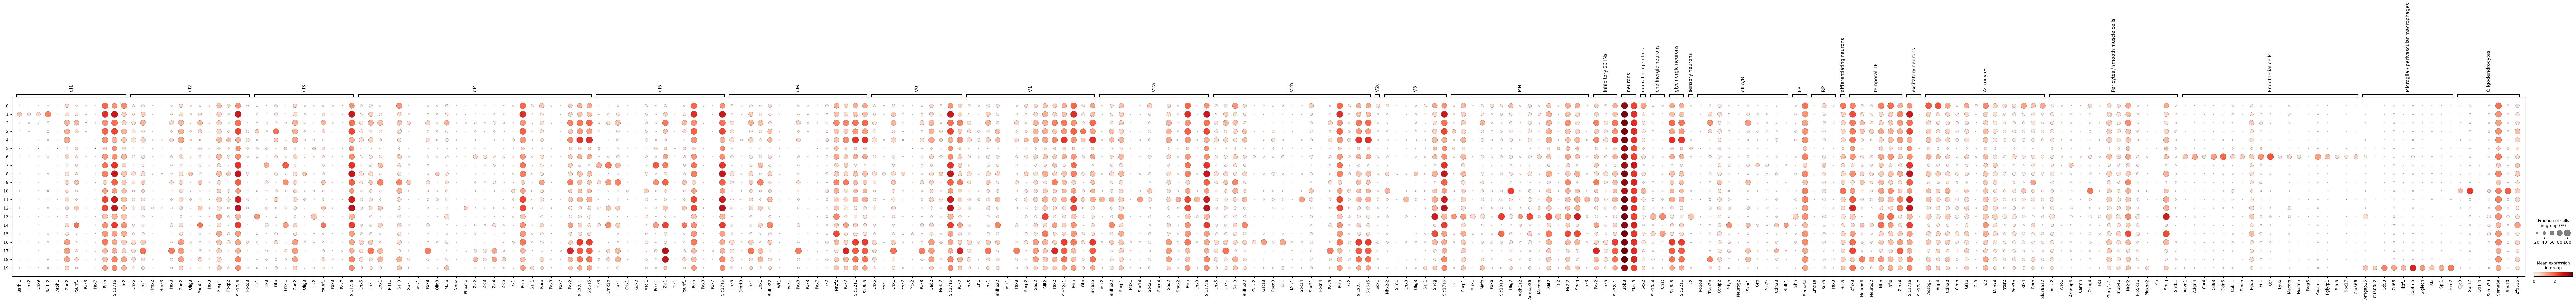

In [11]:
### Subset the neurons
# Only cells with a neuron score above a chosen threshold are included

NEURON_SCORE_THRESHOLD = 0.7

adata_neurons = adata_combined[
    adata_combined.obs["neuron_score"] > NEURON_SCORE_THRESHOLD
].copy()

print(f"All cells: {adata_combined.n_obs:,}")
print(f"Neuronal subset: {adata_neurons.n_obs:,}")
print(
    f"Fraction retained: "
    f"{adata_neurons.n_obs / adata_combined.n_obs:.1%}"
)

# Re-do log normalization only on the neurons
adata_neurons.X = adata_neurons.layers["lognorm"].copy()

sc.pp.scale(adata_neurons,zero_center=False,max_value=10)

# Re-run PCA
sc.pp.pca(adata_neurons,n_comps=30)

# New neighbour graph
sc.pp.neighbors(adata_neurons,n_neighbors=15,n_pcs=30,metric="cosine")

# New leiden clusters
sc.tl.leiden(adata_neurons,flavor="igraph",n_iterations=-1,resolution=0.5)
dp = sc.pl.dotplot(adata_neurons, var_names=custom_SC, groupby="leiden", layer="lognorm", standard_scale=None, dendrogram=False, return_fig=True)
adata_neurons.obs["leiden"] = (adata_neurons.obs["leiden"].cat.remove_unused_categories())

adata_neurons.uns.pop("leiden_colors", None)

# Save the dotplot
dotplot_dir = Path("Output/Leiden")
dotplot_dir.mkdir(parents=True, exist_ok=True)
dp.savefig(dotplot_dir / "neurons_leiden_dotplot.png", dpi=300, bbox_inches="tight")

In [12]:
### Calculate the neuron score for the MADM cells too

# Temporary object used ONLY for calculating comparable neuron scores
adata_for_scoring = ad.concat(
    {
        "Xenium": adata_combined,
        "MADM": adata_madm
    },
    label="score_source",
    join="inner",
    index_unique="__"
)

sc.tl.score_genes(
    adata_for_scoring,
    gene_list=custom_SC["neurons"],
    score_name="neuron_score",
    layer="lognorm",
    use_raw=False
)

# Extract the MADM scores
madm_scores = adata_for_scoring.obs.loc[
    adata_for_scoring.obs["score_source"] == "MADM",
    "neuron_score"
].copy()

# Remove suffix introduced by ad.concat
madm_scores.index = madm_scores.index.str.removesuffix("__MADM")

# Put scores back into the original MADM object
adata_madm.obs["neuron_score"] = madm_scores.reindex(
    adata_madm.obs_names
)

NEURON_SCORE_THRESHOLD = 0.69

adata_madm.obs["passes_neuron_score"] = (
    adata_madm.obs["neuron_score"] > NEURON_SCORE_THRESHOLD
)

adata_madm_neurons = adata_madm[
    adata_madm.obs["passes_neuron_score"]
].copy()

### Save .h5ad files (AnnData objects)
adata_madm_neurons.write_h5ad("Processed/MADM_neurons.h5ad")

print(madm_scores)
print(adata_for_scoring.obs[['cell_id', 'clone', 'neuron_score']])
print(f"All MADM cells: {adata_madm.n_obs}")
print(f"Neuronal MADM cells: {adata_madm_neurons.n_obs}")

computing score 'neuron_score'
    finished: added
    'neuron_score', score of gene set (adata.obs).
    10 total control genes are used. (0:00:01)
102760_clone1_16_0_102760 clone 1      1.455017
102760_clone1_16_1_102760 clone 1      0.977779
102760_clone1_16-2_0_102760 clone 1    0.423074
102760_clone1_16-2_1_102760 clone 1    1.515109
102760_clone1_16-3_0_102760 clone 1    1.488614
102261 clone1_435_0_102261 clone 1     0.779226
102261 clone1_435_1_102261 clone 1     0.995354
102261 clone1_435_2_102261 clone 1     1.361438
102261 clone1_435_3_102261 clone 1     1.462314
102261 clone1_435_4_102261 clone 1     0.806867
102261 clone1_435_5_102261 clone 1     0.690428
102261 clone1_435_6_102261 clone 1     0.939629
102261 clone2_443_0_102261 clone 2     1.033579
102261 clone2_443_1_102261 clone 2     1.607317
102261 clone2_443_2_102261 clone 2     1.091498
102261 clone2_443_3_102261 clone 2     1.970579
102261 clone2_445_0_102261 clone 2     0.639881
102760_clone2_8_0_102760 clone 2   

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:35)


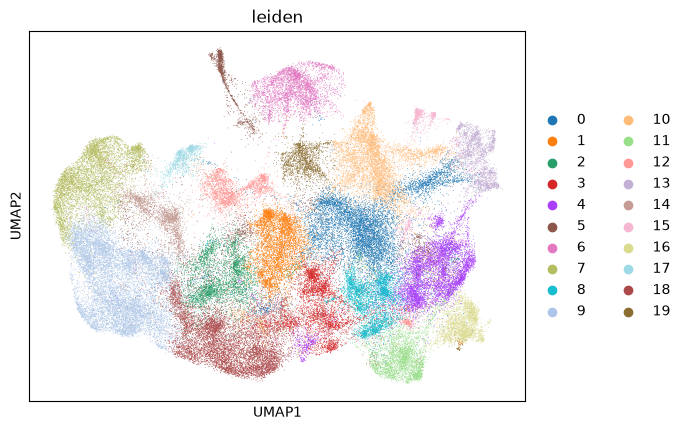

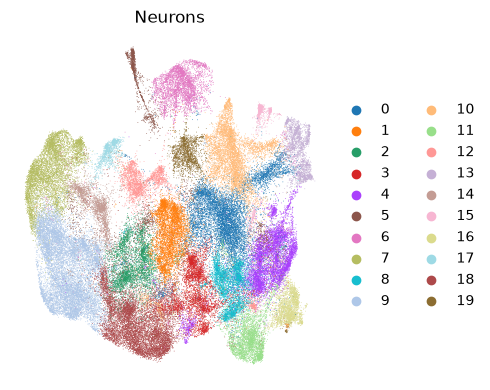

In [13]:
# Neuron UMAP
sc.tl.umap(adata_neurons, min_dist=0.3)
sc.pl.umap(adata_neurons, color="leiden")
# Save the leiden-coloured UMAP
umap_plot_dir = Path("Output/Leiden")
umap_plot_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(
    figsize=(5, 4))

sc.pl.umap(
    adata_neurons,
    color='leiden',
    layer="lognorm",
    cmap="viridis",
    frameon=False,
    ax=ax,
    show=False,
    title='Neurons')

plt.tight_layout()

fig.savefig(
    umap_plot_dir / "neuron_umap_leiden.png",
    dpi=300,
    bbox_inches="tight")

plt.show()
plt.close(fig)
#sc.pl.umap(adata_neurons, color="neuron_score", vmin='p1', vmax='p99',cmap='viridis')

In [14]:
### Save .h5ad files (AnnData objects)
adata_neurons.write_h5ad("Processed/Xen-MADM_neurons_allclusters.h5ad")

In [15]:
### Reload the AnnData object
adata_neurons = sc.read_h5ad("Processed/Xen-MADM_neurons_allclusters.h5ad")

Kept 65976 / 89673 neurons
... be careful when using `max_value` without `zero_center`.
computing PCA
    with n_comps=30


/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:243: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  Version(ad.__version__) < Version("0.9")


    finished (0:00:01)
computing neighbors
    using 'X_pca' with n_pcs = 30


/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:430: FutureWarning: The method obsm_keys is deprecated and will be removed in the future. Use obsm instead of obsm_keys. (e.g. `k in adata.obsm` or `adata.obsm.keys() | {'u'}`)
  if "X_diffmap" in adata.obsm_keys():


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:05)
running Leiden clustering
    finished: found 14 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:02)


/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:2074: FutureWarning: The method obs_keys is deprecated and will be removed in the future. Use obs instead of obs_keys. (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`)
  if group not in [*adata.obs_keys(), adata.obs.index.name]:


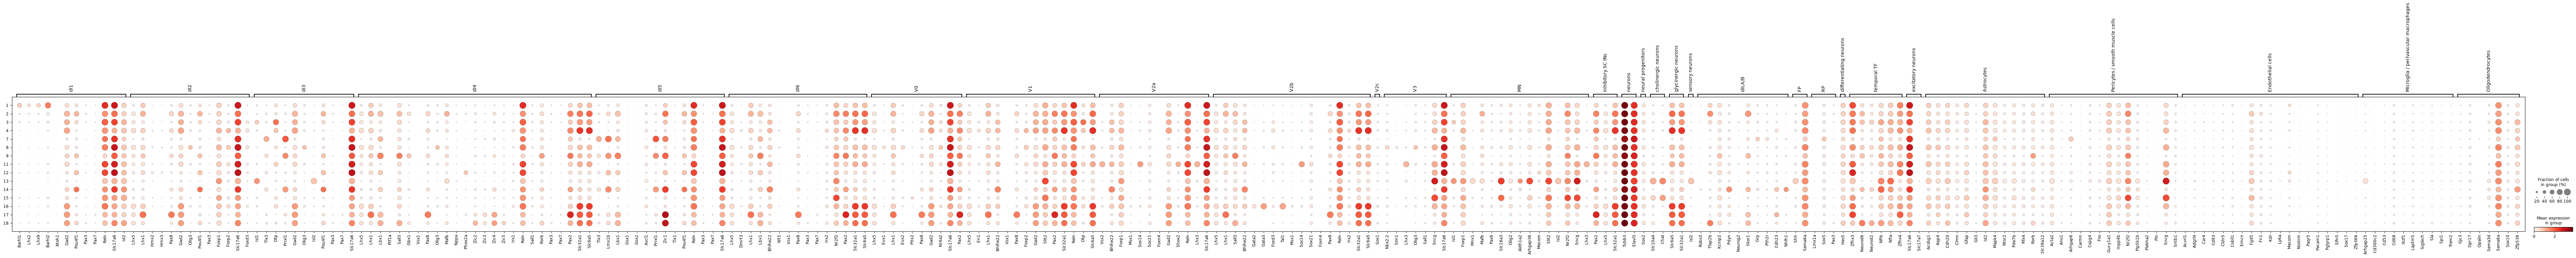

In [16]:
### Exclude some clusters that still contain non-neuronal cell types
CLUSTERS_TO_EXCLUDE = ['0', '5', '6', '10', '19']
# 19 - microglia; 6 - epithelial cells; 0 - astrocytes; 10 - oligos; 5 - VLMC (vascular pericytes)

adata_neurons_reclustered = adata_neurons[~adata_neurons.obs["leiden"].isin(CLUSTERS_TO_EXCLUDE)].copy()
adata_neurons_reclustered.obs["leiden_original"] = (adata_neurons_reclustered.obs["leiden"].astype(str)) # Save the old cluster labels before reclustering

print(f"Kept {adata_neurons_reclustered.n_obs} / {adata_neurons.n_obs} neurons")

adata_neurons_reclustered.obs["leiden"] = (adata_neurons_reclustered.obs["leiden"].astype("category").cat.remove_unused_categories())
adata_neurons_reclustered.uns.pop("leiden_colors", None)

# Reset X to log-normalized expression before scaling
adata_neurons_reclustered.X = (adata_neurons_reclustered.layers["lognorm"].copy())

# Recluster
sc.pp.scale(adata_neurons_reclustered,zero_center=False,max_value=1)

sc.pp.pca(adata_neurons_reclustered,n_comps=30,random_state=0)

sc.pp.neighbors(adata_neurons_reclustered, n_neighbors=15,n_pcs=30,metric="cosine")

sc.tl.leiden(adata_neurons_reclustered,flavor="igraph",n_iterations=-1,resolution=0.8,random_state=0)
dp = sc.pl.dotplot(adata_neurons_reclustered, var_names=custom_SC, groupby="leiden_original", layer="lognorm", standard_scale=None, dendrogram=False)


In [17]:
### Save .h5ad files (AnnData objects)
adata_neurons_reclustered.write_h5ad("Processed/Xen-MADM_neurons_allgenes.h5ad")

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:24)


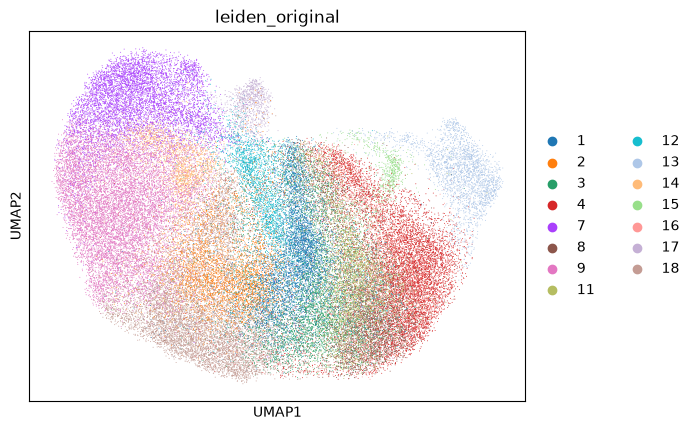

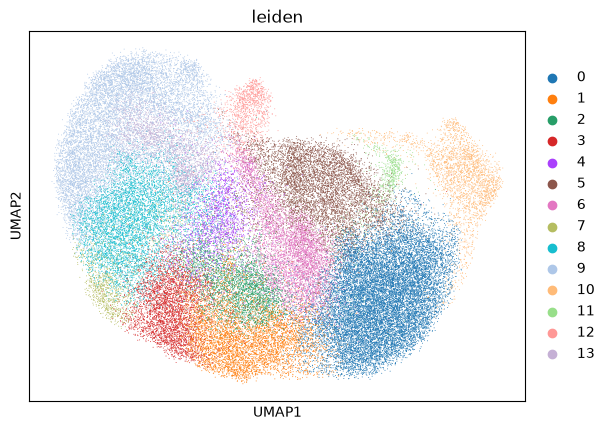

In [18]:
### UMAP of reclustered neurons
sc.tl.umap(adata_neurons_reclustered,min_dist=0.7,random_state=0)
sc.pl.umap(adata_neurons_reclustered,color="leiden_original")
sc.pl.umap(adata_neurons_reclustered,color="leiden")

In [19]:
### Use a subset of neuronal genes for reclustering
SC_neuron_genes = list(dict.fromkeys(gene for genes in SC_neuron.values() for gene in genes))

SC_neuron_genes = [gene for gene in SC_neuron_genes if gene in adata_neurons_reclustered.var_names]

print(f"{len(SC_neuron_genes)} neuron-related genes will be used")

adata_neurons_SCNeuron_genes = adata_neurons_reclustered[:, SC_neuron_genes].copy()
adata_neurons_SCNeuron_genes.X = (adata_neurons_SCNeuron_genes.layers["lognorm"].copy())

sc.pp.scale(adata_neurons_SCNeuron_genes,zero_center=False,max_value=10)

sc.pp.pca(adata_neurons_SCNeuron_genes,n_comps=30,random_state=0)

sc.pp.neighbors(adata_neurons_SCNeuron_genes,n_neighbors=15,n_pcs=30,metric="cosine")

sc.tl.leiden(adata_neurons_SCNeuron_genes,resolution=0.75,flavor="igraph",n_iterations=-1,random_state=0)

109 neuron-related genes will be used
... be careful when using `max_value` without `zero_center`.
computing PCA
    with n_comps=30


/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:243: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  Version(ad.__version__) < Version("0.9")


    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 30


/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:430: FutureWarning: The method obsm_keys is deprecated and will be removed in the future. Use obsm instead of obsm_keys. (e.g. `k in adata.obsm` or `adata.obsm.keys() | {'u'}`)
  if "X_diffmap" in adata.obsm_keys():


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:05)
running Leiden clustering
    finished: found 25 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:02)


computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:25)


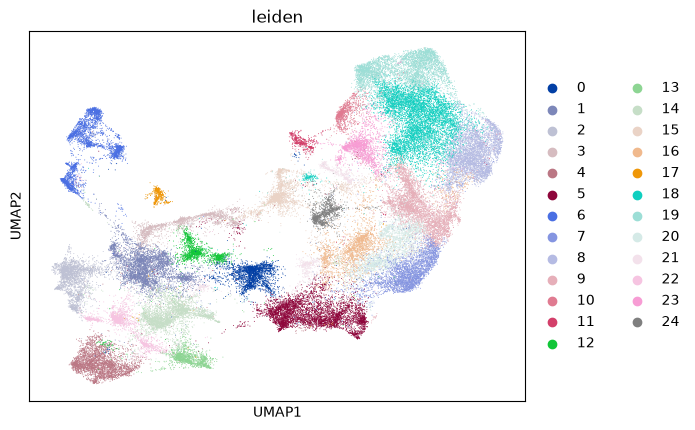

In [20]:
### UMAP of neurons reclustered using SC neuron genes
sc.tl.umap(adata_neurons_SCNeuron_genes,min_dist=0.2,random_state=0)

sc.pl.umap(adata_neurons_SCNeuron_genes,color="leiden")

In [21]:
### Save .h5ad files (AnnData objects)
adata_neurons_SCNeuron_genes.write_h5ad("Processed/Xen-MADM_neurons_SCgenes.h5ad")

In [25]:
adata_neurons_SCNeuron_genes = sc.read_h5ad("Processed/Xen-MADM_neurons_SCgenes.h5ad")

# Master Leiden column that all reclustering steps will update
adata_neurons_SCNeuron_genes.obs["leiden_updated"] = (adata_neurons_SCNeuron_genes.obs["leiden"].astype(str).astype(object))

... be careful when using `max_value` without `zero_center`.
computing PCA
    with n_comps=30
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 30


/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:243: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  Version(ad.__version__) < Version("0.9")
/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:430: FutureWarning: The method obsm_keys is deprecated and will be removed in the future. Use obsm instead of obsm_keys. (e.g. `k in adata.obsm` or `adata.obsm.keys() | {'u'}`)
  if "X_diffmap" in adata.obsm_keys():


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:03)
running Leiden clustering
    finished: found 2 clusters and added
    'V1dI2_reclustered', the cluster labels (adata.obs, categorical) (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:08)


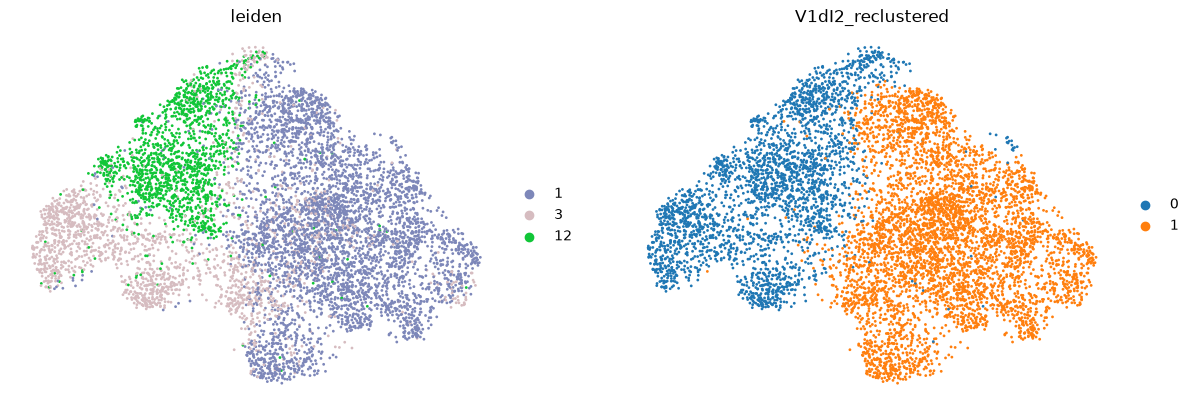

In [26]:
### Recluster the dI2 and V1s because at the moment the border is too much on the side of dI2s. Can tell based on en1 and NT marker expression. 
# The new split with the parameters below is mainly based on slc6a5, slc32a1, and slc17a6

clusters_to_recluster = ["1", "3", "12"]

adata_recluster_V1dI2 = adata_neurons_SCNeuron_genes[adata_neurons_SCNeuron_genes.obs["leiden_updated"].astype(str).isin(clusters_to_recluster)].copy()

# Start from log-normalized expression
adata_recluster_V1dI2.X = adata_recluster_V1dI2.layers["lognorm"].copy()

# Scale within this subset
sc.pp.scale(adata_recluster_V1dI2, zero_center=False, max_value=10)

# PCA
sc.pp.pca(adata_recluster_V1dI2, n_comps=30, random_state=0)

# Neighbors
sc.pp.neighbors(adata_recluster_V1dI2, n_neighbors=30, n_pcs=30, metric="cosine")

# Leiden
sc.tl.leiden(adata_recluster_V1dI2, resolution=0.1, flavor="igraph", n_iterations=-1, random_state=0, key_added="V1dI2_reclustered")

# UMAP
sc.tl.umap(adata_recluster_V1dI2, random_state=0)

sc.pl.umap(adata_recluster_V1dI2, color=["leiden", "V1dI2_reclustered"], frameon=False)

# Update the master clustering layer
new_labels = ("V1dI2_R"+ adata_recluster_V1dI2.obs["V1dI2_reclustered"].astype(str))

adata_neurons_SCNeuron_genes.obs.loc[adata_recluster_V1dI2.obs_names,"leiden_updated"] = new_labels

In [27]:
# ### Recluster the dI4/5s to get more clusters more meaningfully split by subtypes.

# clusters_to_recluster = ["7", "8", "9", "10", "11", "15", "16", "18", "19", "20", "21", "23", "24"]

# adata_recluster = adata_neurons_SCNeuron_genes[adata_neurons_SCNeuron_genes.obs["leiden"].astype(str).isin(clusters_to_recluster)].copy()

# # Start from log-normalized expression
# adata_recluster.X = adata_recluster.layers["lognorm"].copy()

# # Scale within this subset
# sc.pp.scale(adata_recluster, zero_center=False, max_value=10)

# # PCA
# sc.pp.pca(adata_recluster, n_comps=30, random_state=0)

# # Neighbors
# sc.pp.neighbors(adata_recluster, n_neighbors=30, n_pcs=30, metric="cosine")

# # Leiden
# sc.tl.leiden(adata_recluster, resolution=0.3, flavor="igraph", n_iterations=-1, random_state=0, key_added="dI45_reclustered")

# # UMAP
# sc.tl.umap(adata_recluster, random_state=0)

# sc.pl.umap(adata_recluster, color=["leiden", "dI45_reclustered"], frameon=False)

# sc.tl.rank_genes_groups(adata_recluster, groupby="dI45_reclustered", method="wilcoxon")

# sc.pl.rank_genes_groups(adata_recluster, n_genes=20, sharey=False)

In [28]:
# ### Add the new leiden clusters
# # Start with original Leiden labels as strings
# adata_neurons_SCNeuron_genes.obs["dI45_updated"] = (adata_neurons_SCNeuron_genes.obs["leiden"].astype(str))

# # Give the reclustered cells new labels
# # e.g. 1_0, 1_1, 1_2 ... or just R0, R1, R2
# new_labels = ("R" + adata_recluster.obs["dI45_reclustered"].astype(str))

# adata_neurons_SCNeuron_genes.obs.loc[adata_recluster.obs_names,"dI45_updated"] = new_labels

# # Make categorical
# adata_neurons_SCNeuron_genes.obs["dI45_updated"] = (adata_neurons_SCNeuron_genes.obs["dI45_updated"].astype("category"))

# sc.pl.umap(adata_neurons_SCNeuron_genes,color="dI45_updated",frameon=False)

In [29]:
# sc.pl.dotplot(adata_neurons_SCNeuron_genes, var_names=xenium_config.select_genes, groupby="dI45_updated", layer="lognorm", standard_scale=None, dendrogram=False)

... be careful when using `max_value` without `zero_center`.
computing PCA
    with n_comps=30
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 30


/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:243: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  Version(ad.__version__) < Version("0.9")
/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:430: FutureWarning: The method obsm_keys is deprecated and will be removed in the future. Use obsm instead of obsm_keys. (e.g. `k in adata.obsm` or `adata.obsm.keys() | {'u'}`)
  if "X_diffmap" in adata.obsm_keys():


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:02)
running Leiden clustering
    finished: found 2 clusters and added
    'dI45_reclustered', the cluster labels (adata.obs, categorical) (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:04)


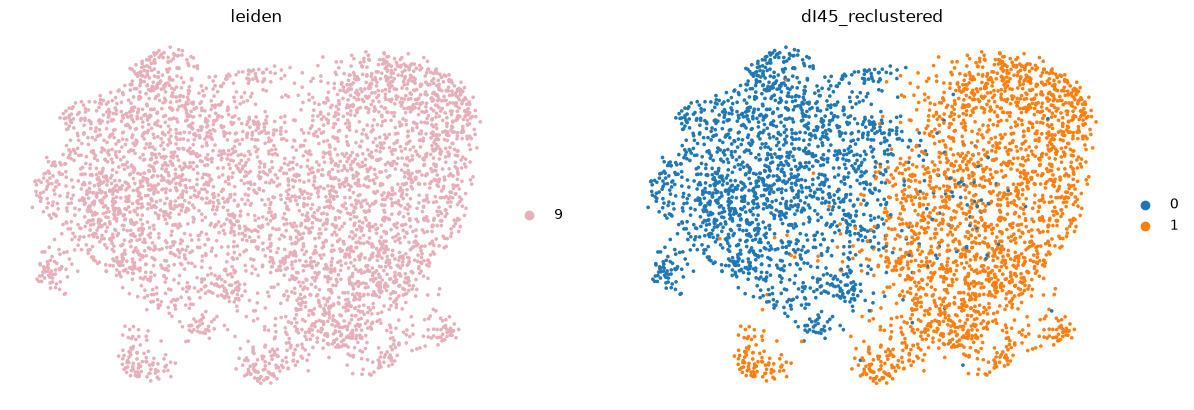

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:01)


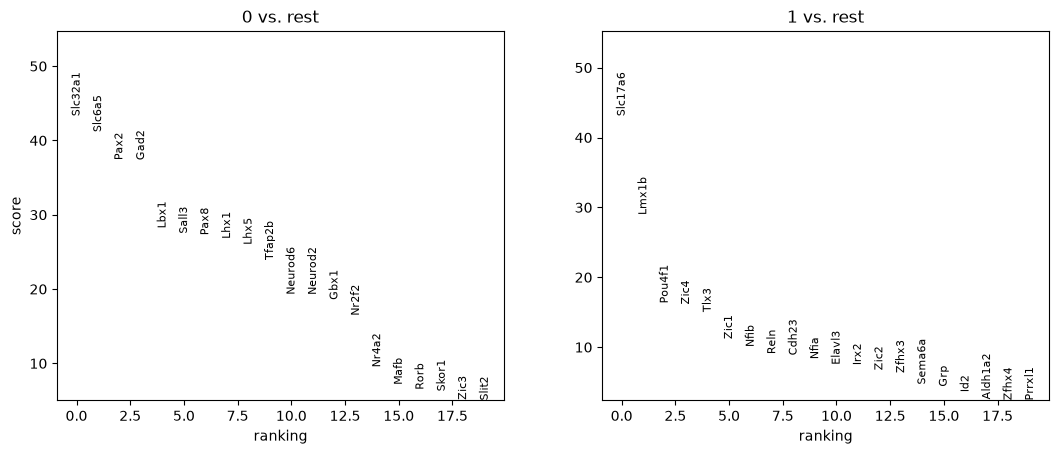

In [30]:
### Recluster dI4/5 cluster 9 because currently it contains excitatory and inhibitory neurons. 
# Reclustering split it based on slc32a1 and slc6a5 vs slc17a6 expression

clusters_to_recluster = ["9"]

adata_recluster_dI45 = adata_neurons_SCNeuron_genes[adata_neurons_SCNeuron_genes.obs["leiden_updated"].astype(str).isin(clusters_to_recluster)].copy()

# Start from log-normalized expression
adata_recluster_dI45.X = adata_recluster_dI45.layers["lognorm"].copy()

# Scale within this subset
sc.pp.scale(adata_recluster_dI45, zero_center=False, max_value=10)

# PCA
sc.pp.pca(adata_recluster_dI45, n_comps=30, random_state=0)

# Neighbors
sc.pp.neighbors(adata_recluster_dI45, n_neighbors=30, n_pcs=30, metric="cosine")

# Leiden
sc.tl.leiden(adata_recluster_dI45, resolution=0.15, flavor="igraph", n_iterations=-1, random_state=0, key_added="dI45_reclustered")

# UMAP
sc.tl.umap(adata_recluster_dI45, random_state=0)

sc.pl.umap(adata_recluster_dI45, color=["leiden", "dI45_reclustered"], frameon=False)

sc.tl.rank_genes_groups(adata_recluster_dI45, groupby="dI45_reclustered", method="wilcoxon")

sc.pl.rank_genes_groups(adata_recluster_dI45, n_genes=20, sharey=False)

# Update the master clustering layers
new_labels = ("dI45_R"+ adata_recluster_dI45.obs["dI45_reclustered"].astype(str))

adata_neurons_SCNeuron_genes.obs.loc[adata_recluster_dI45.obs_names,"leiden_updated"] = new_labels

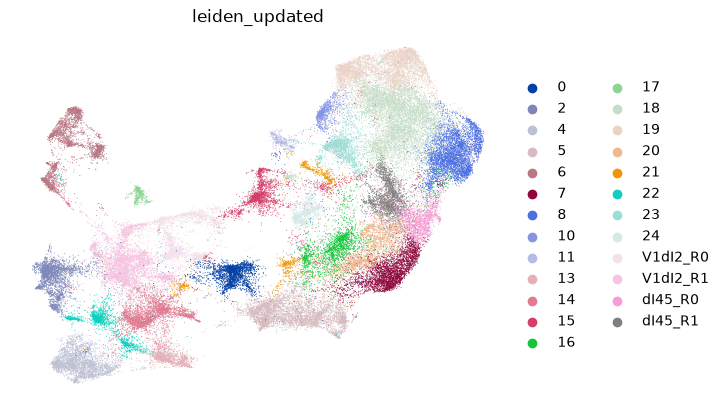

In [31]:
### Updated UMAP
sc.pl.umap(adata_neurons_SCNeuron_genes,color="leiden_updated",frameon=False)

# Make categorical
adata_neurons_SCNeuron_genes.obs["leiden_updated"] = (adata_neurons_SCNeuron_genes.obs["leiden_updated"].astype("category"))

In [32]:
### Save data with reclustering
adata_neurons_SCNeuron_genes.write_h5ad("Processed/Xen-MADM_neurons_SCgenes_reclustered.h5ad")

In [33]:
adata_neurons_SCNeuron_genes = sc.read_h5ad("Processed/Xen-MADM_neurons_SCgenes_reclustered.h5ad")

In [34]:
print(adata_neurons_SCNeuron_genes.n_obs)

65976


In [35]:
### Rename the clusters
cluster_names = {
    "0": "dI3",
    "2": "V2b",
    "4": "V2a",
    "5": "dI1",
    "6": "MN",
    "7": "dI4-1",
    "8": "dI4-2",
    "10": "dI4-3",
    "11": "dI5-1",
    "13": "V3",
    "14": "dI6",
    "15": "dI5-2",
    "16": "dI4-4",
    "17": "V0-2",
    "18": "dI5-3",
    "19": "dI5-4",
    "20": "dI4-5",
    "21": "dI4-6",
    "22": "V0-1",
    "23": "dI5-5",
    "24": "dI4-7",
    "V1dI2_R0": "dI2",
    "V1dI2_R1": "V1",
    "dI45_R0": "dI4-8",
    "dI45_R1": "dI5-6"
}

adata_neurons_SCNeuron_genes.obs["cell_type"] = (adata_neurons_SCNeuron_genes.obs["leiden_updated"].astype(str).map(cluster_names))

# Sort
cluster_names_list = ["dI1", "dI2", "dI3", "dI4-1", "dI4-2", "dI4-3", "dI4-4", "dI4-5", "dI4-6", "dI4-7", "dI4-8", "dI5-1", "dI5-2", "dI5-3", "dI5-4", "dI5-5", "dI5-6", "dI6", "V0-1", "V0-2", "V1", "V2a", "V2b", "MN", "V3"]

adata_neurons_SCNeuron_genes.obs["cell_type"] = pd.Categorical(adata_neurons_SCNeuron_genes.obs["cell_type"],categories=cluster_names_list,ordered=True)

In [36]:
### Define consistent colours for the clusters/cell types

# Leiden cluster gets the colour of its assigned cell type
leiden_color_map = {
    leiden: xenium_config.cell_type_colors[cell_type]
    for leiden, cell_type in cluster_names.items()
}

# Leiden colours, in exactly the category order Scanpy expects
adata_neurons_SCNeuron_genes.uns["leiden_colors"] = [
    leiden_color_map[str(cluster)]
    for cluster in adata_neurons_SCNeuron_genes.obs["leiden_updated"].cat.categories
]

# Cell-type colours, in exactly the category order Scanpy expects
adata_neurons_SCNeuron_genes.uns["cell_type_colors"] = [
    xenium_config.cell_type_colors[cell_type]
    for cell_type in adata_neurons_SCNeuron_genes.obs["cell_type"].cat.categories
]

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:2074: FutureWarning: The method obs_keys is deprecated and will be removed in the future. Use obs instead of obs_keys. (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`)
  if group not in [*adata.obs_keys(), adata.obs.index.name]:


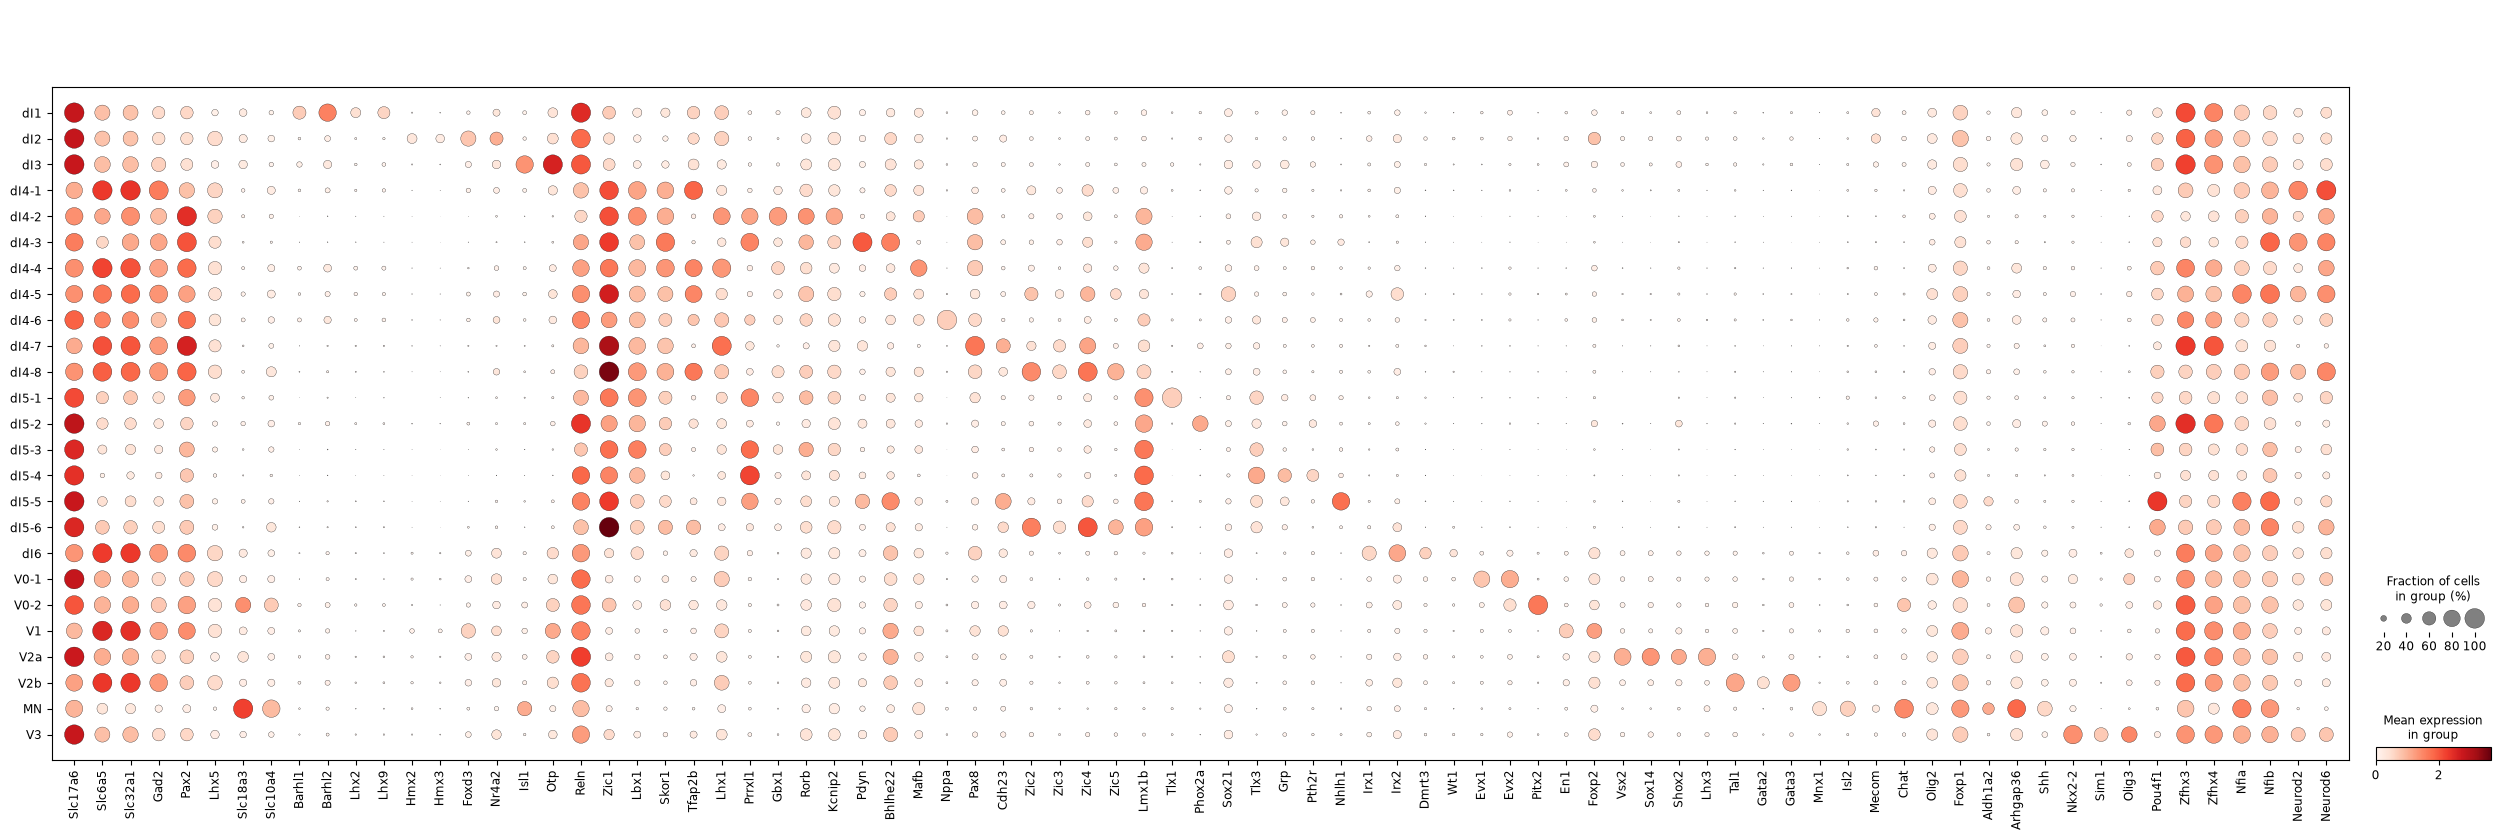

In [37]:
### Updated dot plot
dp = sc.pl.dotplot(adata_neurons_SCNeuron_genes, var_names=xenium_config.select_genes, groupby="cell_type", layer="lognorm", standard_scale=None, dendrogram=False, return_fig=True)
dp.savefig(dotplot_dir / "neurons_reclustered_leiden_dotplot_select_genes.png", dpi=300, bbox_inches="tight")

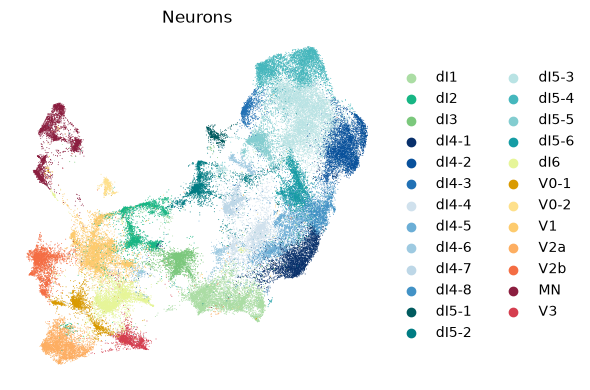

In [38]:
### UMAP with cell-type names
fig, ax = plt.subplots(
    figsize=(6, 4))

sc.pl.umap(
    adata_neurons_SCNeuron_genes,
    color='cell_type',
    layer="lognorm",
    cmap="viridis",
    frameon=False,
    ax=ax,
    show=False,
    title='Neurons')

plt.tight_layout()

fig.savefig(
    umap_plot_dir / "neuron_umap_leiden.png",
    dpi=300,
    bbox_inches="tight")

plt.show()
plt.close(fig)

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:2074: FutureWarning: The method obs_keys is deprecated and will be removed in the future. Use obs instead of obs_keys. (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`)
  if group not in [*adata.obs_keys(), adata.obs.index.name]:


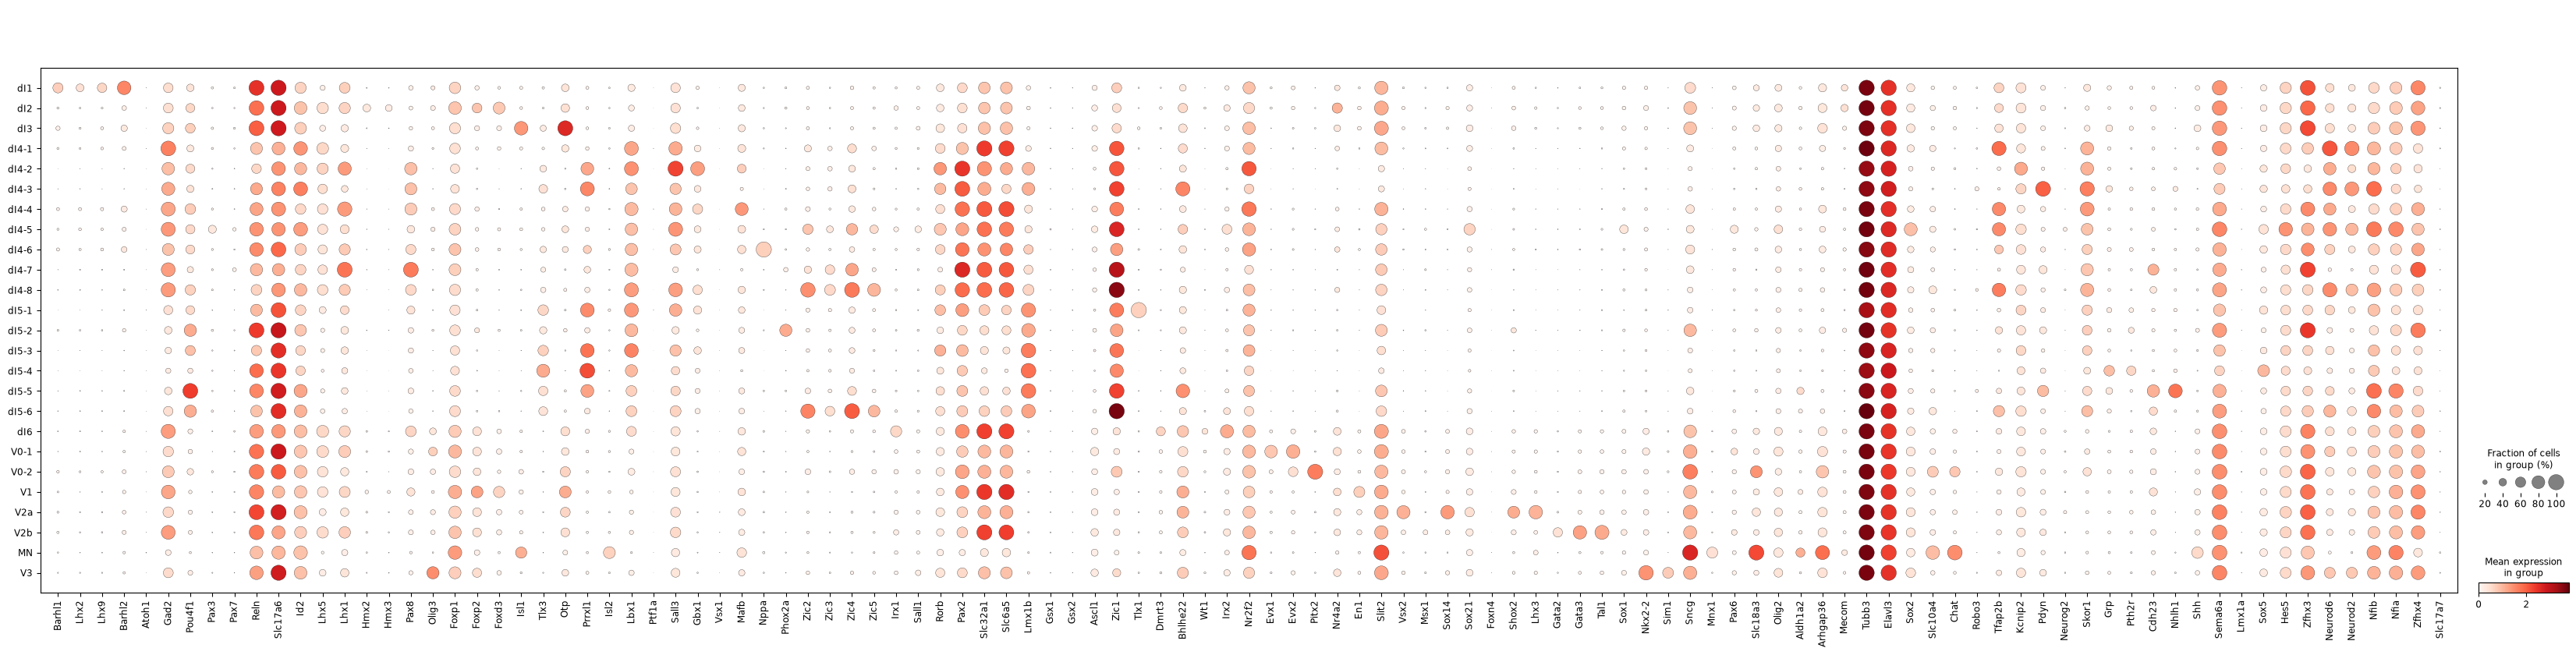

In [39]:
### Dotplot of neurons reclustered using SC neuron genes
dp = sc.pl.dotplot(adata_neurons_SCNeuron_genes, var_names=SC_neuron_genes, groupby="cell_type", layer="lognorm", standard_scale=None, dendrogram=False, return_fig = True)
dp.savefig(dotplot_dir / "neurons_reclustered_leiden_dotplot.png", dpi=300, bbox_inches="tight")

In [ ]:
# ### Feature plots

# for gene in SC_neuron_genes:

#     fig, axes = plt.subplots(
#         1, 2,
#         figsize=(10, 4)
#     )

#     # Feature expression
#     sc.pl.umap(
#         adata_neurons_SCNeuron_genes,
#         color=gene,
#         layer="lognorm",
#         cmap="viridis",
#         frameon=False,
#         ax=axes[0],
#         show=False,
#         title=gene
#     )

#     # Leiden clusters
#     sc.pl.umap(
#         adata_neurons_SCNeuron_genes,
#         color="leiden",
#         frameon=False,
#         ax=axes[1],
#         show=False,
#         title="Leiden"
#     )

# # Make and save one UMAP feature plot per gene
# # Output folder
# feature_plot_dir = Path("Output/FeaturePlotsNeurons")
# feature_plot_dir.mkdir(parents=True, exist_ok=True)
# for gene in SC_neuron_genes:

#     fig, ax = plt.subplots(
#         figsize=(5, 4)
#     )

#     sc.pl.umap(
#         adata_neurons_SCNeuron_genes,
#         color=gene,
#         layer="lognorm",
#         cmap="viridis",
#         frameon=False,
#         ax=ax,
#         show=False,
#         title=gene
#     )

#     plt.tight_layout()

#     fig.savefig(
#         feature_plot_dir / f"{gene}.png",
#         dpi=300,
#         bbox_inches="tight"
#     )

#     plt.show()
#     plt.close(fig)

In [ ]:
### Spatial plots

region = "Region 60_3"

sub = adata_neurons_SCNeuron_genes[
    adata_neurons_SCNeuron_genes.obs["region"] == region
].copy()

fig, ax = plt.subplots(figsize=(7, 7))

for cluster in adata_neurons_SCNeuron_genes.obs["cell_type"].cat.categories:

    mask = sub.obs["cell_type"] == cluster

    ax.scatter(
        sub.obs.loc[mask, "spatial_x"],
        sub.obs.loc[mask, "spatial_y"],
        s=0.3,
        color=xenium_config.cell_type_colors[cluster],
        label=cluster
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(region)

ax.legend(
    title="Cell types",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=2
)

# Save the figure
plot_dir = Path("Output/Leiden")
plot_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(
    plot_dir / "Spatial_leiden_60_3.svg",
    dpi=300,
    bbox_inches="tight")
plt.tight_layout()
plt.show()

In [ ]:
### Spatial plots

region = "Region 60_8"

sub = adata_neurons_SCNeuron_genes[
    adata_neurons_SCNeuron_genes.obs["region"] == region
].copy()

fig, ax = plt.subplots(figsize=(7, 7))

for cluster in adata_neurons_SCNeuron_genes.obs["cell_type"].cat.categories:

    mask = sub.obs["cell_type"] == cluster

    ax.scatter(
        sub.obs.loc[mask, "spatial_x"],
        sub.obs.loc[mask, "spatial_y"],
        s=0.6,
        color=xenium_config.cell_type_colors[cluster],
        label=cluster
    )

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(region)

ax.legend(
    title="Cell types",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=2
)

# Save the figure
plot_dir = Path("Output/Leiden")
plot_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(
    plot_dir / "Spatial_leiden_60_8.svg",
    dpi=300,
    bbox_inches="tight")
plt.tight_layout()
plt.show()

In [40]:
### Save .h5ad files (AnnData objects)
adata_neurons_SCNeuron_genes.write_h5ad("Processed/Xen-MADM_neurons_SCgenes_reclustered.h5ad")
adata_MADM_neurons.write_h5ad("Processed/MADM_neurons.h5ad")

NameError: name 'adata_MADM_neurons' is not defined

In [ ]:
### Save a .h5ad file with the reclustered neurons but including all genes
adata_neurons_reclustered_all_genes = adata_neurons_reclustered.copy()

# Keep exactly the cells in final neuronal clustering
adata_neurons_reclustered_all_genes = adata_neurons_reclustered_all_genes[adata_neurons_SCNeuron_genes.obs_names].copy()

# Transfer final cluster annotations
for col in ["leiden_updated", "cell_type"]:
    adata_neurons_reclustered_all_genes.obs[col] = (
        adata_neurons_SCNeuron_genes.obs[col].copy()
    )

# Transfer UMAP coordinates
adata_neurons_reclustered_all_genes.obsm["X_umap"] = (
    adata_neurons_SCNeuron_genes.obsm["X_umap"].copy()
)

# Transfer cell-type colors
adata_neurons_reclustered_all_genes.uns["cell_type_colors"] = (
    adata_neurons_SCNeuron_genes.uns["cell_type_colors"].copy()
)

adata_neurons_reclustered_all_genes.write_h5ad("Processed/Xen-MADM_neurons_SCgenes_reclustered_all_genes.h5ad")

In [42]:
for name, adata in [
    ("Combined", adata_combined),
    ("Neurons", adata_neurons),
    ("Neurons reclustered", adata_neurons_reclustered),
    ("SC neuron genes", adata_neurons_SCNeuron_genes),
    ("Neurons all genes", adata_neurons_reclustered_all_genes),
]:
    print(f"{name}: {adata.n_obs} cells, {adata.n_vars} genes")

Combined: 186963 cells, 347 genes
Neurons: 89673 cells, 347 genes
Neurons reclustered: 65976 cells, 347 genes
SC neuron genes: 65976 cells, 109 genes
Neurons all genes: 65976 cells, 347 genes
